In [ ]:
# ==============================================================================
# INSTALASI DEPENDENSI (Jalankan sel ini HANYA jika pustaka belum terpasang)
# Hilangkan tanda pagar (#) pada baris di bawah untuk memasang dependensi:
# ==============================================================================
# !pip install numpy pandas matplotlib scipy scikit-learn
# Atau instal seluruh dependensi modul melalui file requirements.txt:
# !pip install -r ../../requirements.txt


# Praktik 3. Dari Spektrum Pantulan ke Sifat Tanah

ASD FieldSpec 4 merekam **spektrum pantulan**, bukan nilai sifat tanah. Nilai sifat tanah baru diperoleh setelah spektrum dihubungkan dengan hasil laboratorium melalui model kalibrasi. Notebook ini menelusuri jalan tersebut dengan pustaka spektral vis-NIR 350–2.500 nm: membaca spektrum, mengenali fitur serapan, memberi praolah, lalu melatih dan menilai model *Partial Least Squares Regression* (PLSR).

Pegangan membaca notebook: jalankan sel dari atas ke bawah dengan **Shift + Enter**, lalu baca keluarannya sebelum lanjut. Rujukan konsep ada di Modul 7, Gambar 7.3 dan 7.4.

**Catatan data.** Pustaka ini merupakan hasil pengujian sampel tanah dari Site Gunung Madu Plantation (GMP), Lampung, jadi bukan dari Sub-DAS Bompon. Kode sampel `S3 L2` ditafsirkan sebagai profil S3 lapisan 2. Model dalam notebook ini dilatih dari tanah GMP dan dipakai untuk latihan. Untuk tanah dari tempat lain, hasilnya hanya pendekatan sampai diuji dengan sampel setempat (Modul 7).

## 1. Menyiapkan lingkungan kerja

In [1]:
import os, sys

# Di Google Colab: pasang pustaka lalu sambungkan Drive. Di Jupyter lokal bagian ini dilewati.
if 'google.colab' in sys.modules:
    !pip -q install numpy pandas scipy scikit-learn matplotlib
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Pelatihan/data/praktik-3')   # sesuaikan dengan lokasi folder Anda

os.makedirs('hasil', exist_ok=True)
print('Folder kerja:', os.path.basename(os.getcwd()))

Folder kerja: praktik-3


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_val_predict
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9})

## 2. Membaca pustaka spektral

Setiap baris adalah satu sampel. Kolom `w350` sampai `w2500` berisi pantulan pada setiap panjang gelombang, sedangkan kolom lainnya berisi hasil laboratorium.

In [3]:
data = pd.read_csv('spektra_visnir_gmp.csv.gz')
kolom_spektrum = [k for k in data.columns if k.startswith('w') and k[1:].isdigit()]
kolom_lab = [k for k in data.columns if k not in kolom_spektrum and k != 'sampel']
panjang_gel = np.array([int(k[1:]) for k in kolom_spektrum], dtype=float)
data = data.copy()
data['profil'] = data['sampel'].str.extract(r'^(S\d+)')[0]

print('Sampel :', len(data))
print('Profil :', data['profil'].nunique())
print('Lapisan per profil:', data.groupby('profil').size().value_counts().sort_index().to_dict())
print('Kanal  :', len(panjang_gel), 'dari', panjang_gel.min(), 'sampai', panjang_gel.max(), 'nm')
print('Sifat tanah:', kolom_lab)
data[['sampel', 'profil', 'c_organik', 'n_total', 'clay', 'sand', 'ph_h2o', 'kpk', 'p_tersedia']].head(6)

Sampel : 274
Profil : 71
Lapisan per profil: {2: 5, 3: 4, 4: 58, 5: 4}
Kanal  : 2151 dari 350.0 sampai 2500.0 nm
Sifat tanah: ['clay', 'silt', 'sand', 'ph_h2o', 'ph_kcl', 'c_organik', 'kadar_air_aktual', 'kapasitas_lapang', 'titik_layu_permanen', 'air_tersedia', 'bv', 'bj', 'porositas', 'kpk', 'kejenuhan_basa', 'n_total', 'k_tersedia', 'p_tersedia', 'c/n', 'ca', 'mg', 'al']


,sampel,profil,c_organik,n_total,clay,sand,ph_h2o,kpk,p_tersedia
0,S3 L3,S3,0.94,0.06,39.24,53.84,4.83,3.57,9.0
1,S56 L2,S56,2.28,0.08,28.16,61.84,5.95,3.74,36.0
2,S56 L3,S56,0.71,0.10,30.16,57.84,5.86,4.99,31.0
3,S56 L4,S56,0.66,0.08,54.16,35.84,4.78,4.76,6.0
4,S56 L1,S56,1.25,0.06,26.16,65.84,5.91,3.87,42.0
5,S3 L1,S3,1.71,0.12,31.24,57.84,6.12,4.95,81.0


**Periksa datanya dulu.** Dua hal perlu diketahui sebelum memodelkan: sampel yang tidak memiliki hasil laboratorium, dan nilai yang tidak mungkin secara fisik. Sampel tanpa hasil laboratorium tidak dapat dipakai melatih model, tetapi berguna pada Bagian 11.

In [4]:
tanpa_lab = data[data['clay'].isna()].reset_index(drop=True)
print('Sampel tanpa hasil laboratorium:', tanpa_lab['sampel'].tolist())
print('C-organik bernilai 0:')
print(data.loc[data['c_organik'] == 0, ['sampel', 'c_organik', 'n_total']].to_string(index=False))

# C-organik 0 tidak mungkin pada tanah yang N-totalnya 0,11, sehingga diperlakukan sebagai data kosong
data.loc[data['c_organik'] == 0, 'c_organik'] = np.nan

data_lab = data[data['clay'].notna()].reset_index(drop=True)
profil = data_lab['profil'].values
data_lab[['c_organik', 'n_total', 'clay', 'silt', 'sand', 'ph_h2o', 'kpk', 'p_tersedia', 'k_tersedia']].describe().T[['count', 'min', '50%', 'mean', 'max', 'std']].round(2)

Sampel tanpa hasil laboratorium: ['S47 L5', 'S73 L1', 'S73 L2', 'S73 L3', 'S73 L4', 'S45 L1', 'S45 L2', 'S45 L3', 'S45 L4']
C-organik bernilai 0:
sampel  c_organik  n_total
 S4 L3        0.0     0.11


,count,min,50%,mean,max,std
c_organik,264.0,0.27,1.34,1.33,4.10,0.62
n_total,265.0,0.02,0.12,0.12,0.30,0.04
clay,265.0,17.24,38.88,40.48,74.90,12.29
silt,265.0,1.28,9.28,10.26,25.64,5.25
sand,265.0,1.48,51.84,49.27,73.12,13.79
ph_h2o,265.0,4.11,5.44,5.48,7.00,0.57
kpk,265.0,1.25,5.89,6.61,20.90,3.29
p_tersedia,265.0,0.00,30.00,38.84,179.30,34.89
k_tersedia,265.0,0.02,0.21,0.24,0.90,0.15


## 3. Melihat spektrum

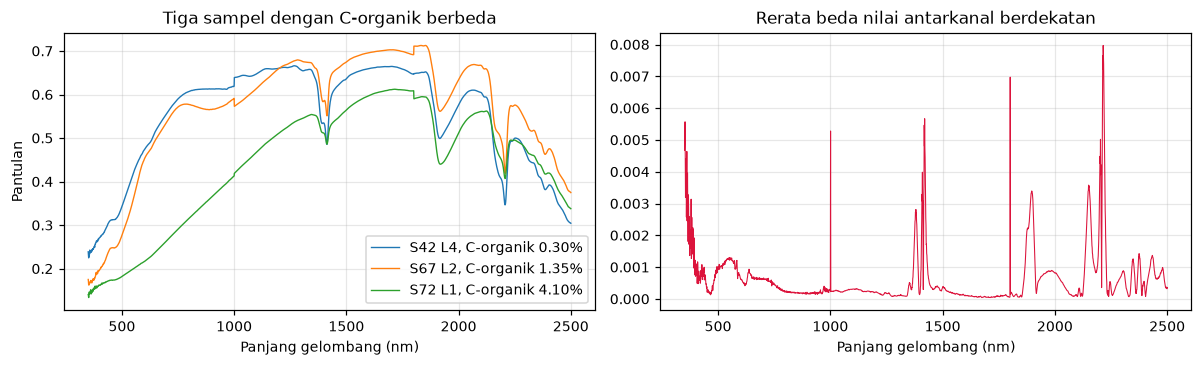

Beda antarkanal 350-399 nm: 0.00242
Beda antarkanal 400-2500 nm: 0.00059


In [5]:
urut = data_lab.dropna(subset=['c_organik']).sort_values('c_organik')
contoh = urut.iloc[[2, len(urut) // 2, -1]]
S = data_lab[kolom_spektrum].values
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for _, b in contoh.iterrows():
    ax[0].plot(panjang_gel, b[kolom_spektrum].values.astype(float), lw=.9, label=f"{b['sampel']}, C-organik {b['c_organik']:.2f}%")
ax[0].set(title='Tiga sampel dengan C-organik berbeda', xlabel='Panjang gelombang (nm)', ylabel='Pantulan'); ax[0].legend()
ax[1].plot(panjang_gel[1:], np.abs(np.diff(S, axis=1)).mean(axis=0), color='crimson', lw=.7)
ax[1].set(title='Rerata beda nilai antarkanal berdekatan', xlabel='Panjang gelombang (nm)')
plt.tight_layout(); plt.savefig('hasil/spektrum_contoh.png', dpi=150); plt.show()
print('Beda antarkanal 350-399 nm:', round(np.abs(np.diff(S[:, panjang_gel < 400], axis=1)).mean(), 5))
print('Beda antarkanal 400-2500 nm:', round(np.abs(np.diff(S[:, panjang_gel >= 400], axis=1)).mean(), 5))

Spektrum yang halus seharusnya hampir tidak berubah antarkanal yang berdekatan. Di bawah 400 nm, nilainya melompat-lompat, yang menandakan derau, sehingga pemodelan hanya memakai 400–2.500 nm. Lonjakan sempit di 1.000 nm dan 1.800 nm berada tepat pada batas antardetektor alat, sedangkan lonjakan lainnya mengikuti tepi fitur serapan.

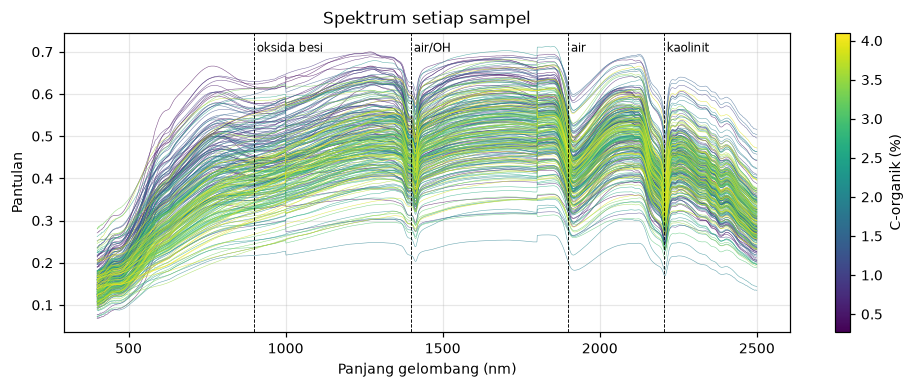

In [6]:
pilih = panjang_gel >= 400
wl = panjang_gel[pilih]
R = data_lab[kolom_spektrum].values[:, pilih]

fig, ax = plt.subplots(figsize=(9, 3.6))
ada = np.where(data_lab['c_organik'].notna())[0]
urut_c = ada[np.argsort(data_lab['c_organik'].values[ada])]
warna = plt.cm.viridis(np.linspace(0, 1, len(urut_c)))
for w, i in zip(warna, urut_c):
    ax.plot(wl, R[i], color=w, lw=.35, alpha=.7)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(data_lab['c_organik'].min(), data_lab['c_organik'].max()))
plt.colorbar(sm, ax=ax, label='C-organik (%)')
for pos, nama in [(900, 'oksida besi'), (1400, 'air/OH'), (1900, 'air'), (2205, 'kaolinit')]:
    ax.axvline(pos, color='k', lw=.6, ls='--'); ax.text(pos + 8, ax.get_ylim()[1] * .94, nama, fontsize=8)
ax.set(title='Spektrum setiap sampel', xlabel='Panjang gelombang (nm)', ylabel='Pantulan')
plt.tight_layout(); plt.savefig('hasil/spektrum_semua_sampel.png', dpi=150); plt.show()

## 4. Membaca fitur serapan

Posisi serapan yang ditandai di atas mengikuti Modul 7 (Molin & Tavares, 2019). Dua hubungan diuji di sini. Yang pertama adalah kedalaman serapan kaolinit di sekitar 2.205 nm terhadap kadar lempung, dengan garis kontinum sederhana antara 2.120 nm dan 2.250 nm. Yang kedua adalah pantulan wilayah tampak terhadap C-organik, karena Modul 4 menyebut bahan organik menurunkan pantulan pada wilayah tersebut.

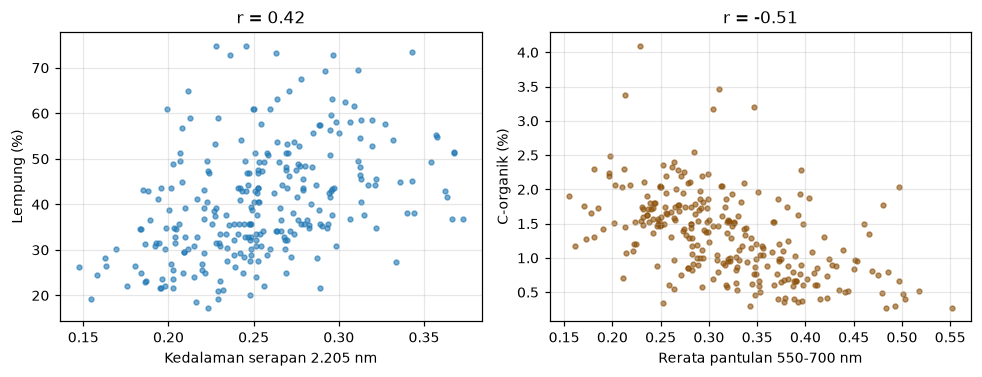

Korelasi kedalaman serapan dengan lempung: 0.42
Korelasi pantulan tampak dengan C-organik: -0.51


In [7]:
def kedalaman_serapan(R, wl, kiri=2120, pusat=2205, kanan=2250):
    i, c, k = [np.argmin(np.abs(wl - v)) for v in (kiri, pusat, kanan)]
    kontinum = R[:, i] + (R[:, k] - R[:, i]) * (wl[c] - wl[i]) / (wl[k] - wl[i])
    return 1 - R[:, c] / kontinum

kedalaman = kedalaman_serapan(R, wl)
tampak = R[:, (wl >= 550) & (wl <= 700)].mean(axis=1)
m_c = data_lab['c_organik'].notna().values
r_lempung = np.corrcoef(kedalaman, data_lab['clay'])[0, 1]
r_corg = np.corrcoef(tampak[m_c], data_lab['c_organik'][m_c])[0, 1]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].scatter(kedalaman, data_lab['clay'], s=10, alpha=.6)
ax[0].set(xlabel='Kedalaman serapan 2.205 nm', ylabel='Lempung (%)', title=f'r = {r_lempung:.2f}')
ax[1].scatter(tampak[m_c], data_lab['c_organik'][m_c], s=10, alpha=.6, color='#8c510a')
ax[1].set(xlabel='Rerata pantulan 550-700 nm', ylabel='C-organik (%)', title=f'r = {r_corg:.2f}')
plt.tight_layout(); plt.savefig('hasil/fitur_serapan.png', dpi=150); plt.show()
print('Korelasi kedalaman serapan dengan lempung:', round(r_lempung, 2))
print('Korelasi pantulan tampak dengan C-organik:', round(r_corg, 2))

## 5. Praolah spektrum

Sebagian besar keragaman spektrum disebabkan oleh ukuran partikel dan hamburan, bukan komposisi kimia (Barnes et al., 1989). *Standard Normal Variate* (SNV) meredam gangguan tersebut, sedangkan turunan pertama Savitzky–Golay menajamkan fitur serapan. Keduanya dihitung per spektrum, sehingga tidak ada informasi yang bocor antarsampel.

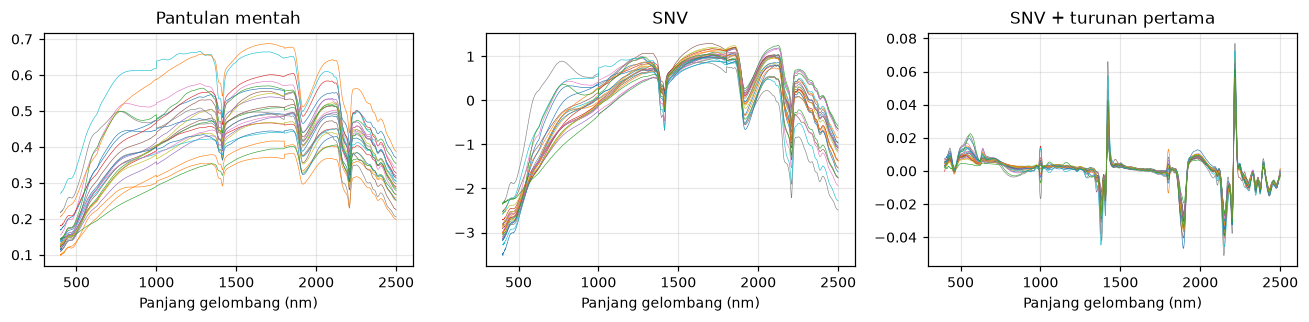

In [8]:
def snv(A):
    return (A - A.mean(axis=1, keepdims=True)) / A.std(axis=1, keepdims=True)

def turunan(A):
    return savgol_filter(A, window_length=21, polyorder=2, deriv=1, axis=1)

praolah = {'Pantulan mentah': lambda A: A,
           'SNV': snv,
           'SNV + turunan pertama': lambda A: turunan(snv(A))}

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, (nama, f) in zip(ax, praolah.items()):
    a.plot(wl, f(R)[::12].T, lw=.4)
    a.set(title=nama, xlabel='Panjang gelombang (nm)')
plt.tight_layout(); plt.savefig('hasil/praolah.png', dpi=150); plt.show()

Korelogram memperlihatkan wilayah spektrum yang berhubungan dengan sifat tanah, sebelum dan sesudah praolah.

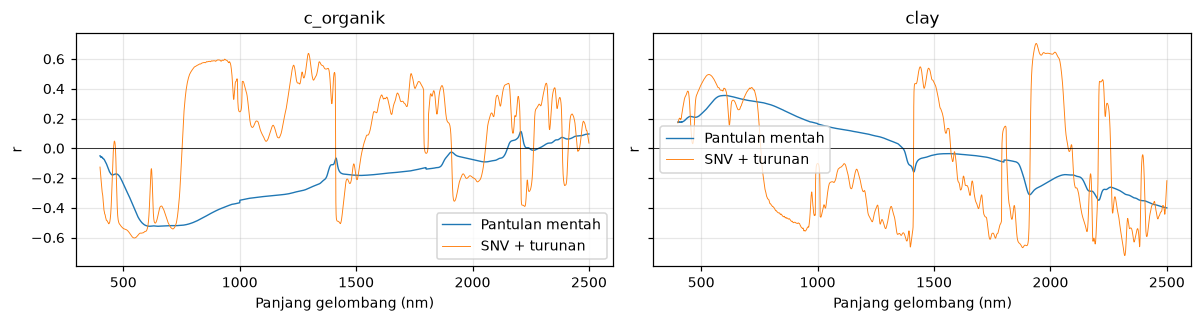

In [9]:
def korelogram(A, y):
    return np.array([np.corrcoef(A[:, j], y)[0, 1] for j in range(A.shape[1])])

fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for a, t in zip(ax, ['c_organik', 'clay']):
    m = data_lab[t].notna().values
    a.plot(wl, korelogram(R[m], data_lab[t][m]), lw=.9, label='Pantulan mentah')
    a.plot(wl, korelogram(turunan(snv(R))[m], data_lab[t][m]), lw=.6, label='SNV + turunan')
    a.axhline(0, color='k', lw=.5); a.set(title=t, xlabel='Panjang gelombang (nm)', ylabel='r'); a.legend()
plt.tight_layout(); plt.savefig('hasil/korelogram.png', dpi=150); plt.show()

## 6. Ukuran ketelitian

Fungsi berikut menghitung ukuran pada Modul 7 dan Modul 8. MEC adalah bagian keragaman yang dijelaskan terhadap garis 1:1 dan bernilai negatif jika model lebih buruk daripada menebak rata-rata. RPD adalah simpangan baku dibagi RMSE. RPIQ adalah jangkauan antarkuartil dibagi RMSE.

In [10]:
def ukuran(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float).ravel()
    e = p - y
    rmse = np.sqrt(np.mean(e ** 2))
    return {'ME': e.mean(), 'RMSE': rmse,
            'MEC': 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
            'R2': np.corrcoef(y, p)[0, 1] ** 2,
            'RPD': y.std(ddof=1) / rmse,
            'RPIQ': (np.percentile(y, 75) - np.percentile(y, 25)) / rmse}

## 7. Cara membagi data menentukan angka yang dilaporkan

Ini bagian terpenting dari notebook. Sampel dari satu profil, yaitu lapisan-lapisan pada satu titik, saling mirip. Bandingkan dua cara validasi silang pada model yang sama:

1. **Acak per sampel**, lapisan dari profil yang sama dapat masuk data latih sekaligus data uji.
2. **Per profil**, semua lapisan satu profil selalu berada di sisi yang sama. Inilah yang paling mendekati keadaan ketika model dipakai pada titik baru.

In [11]:
A = turunan(snv(R))
N_KOMP = 8
baris = []
for t in ['c_organik', 'clay']:
    m = data_lab[t].notna().values
    y = data_lab[t].values[m]
    pls = PLSRegression(N_KOMP)
    p1 = cross_val_predict(pls, A[m], y, cv=KFold(5, shuffle=True, random_state=1))
    p2 = cross_val_predict(pls, A[m], y, cv=GroupKFold(5), groups=profil[m])
    baris.append({'Sifat': t, 'Skema': '1. Acak per sampel', **ukuran(y, p1)})
    baris.append({'Sifat': t, 'Skema': '2. Per profil', **ukuran(y, p2)})
bocoran = pd.DataFrame(baris).round(2)
bocoran.to_csv('hasil/perbandingan_skema_validasi.csv', index=False)
bocoran

,Sifat,Skema,ME,RMSE,MEC,R2,RPD,RPIQ
0,c_organik,1. Acak per sampel,0.00,0.46,0.44,0.46,1.34,1.87
1,c_organik,2. Per profil,-0.02,0.47,0.40,0.43,1.30,1.81
2,clay,1. Acak per sampel,-0.11,7.20,0.66,0.66,1.71,2.30
3,clay,2. Per profil,-0.17,8.93,0.47,0.49,1.38,1.85


**Diskusi.** Skema pertama memberi angka lebih baik karena model melihat lapisan lain dari profil yang sama saat dilatih. Selisihnya tampak jelas pada lempung. Mulai sekarang semua penilaian memakai pembagian **per profil**.

## 8. Memilih praolah dan jumlah komponen

Jumlah komponen laten terlalu sedikit membuat model kurang pas, terlalu banyak membuatnya hafal derau. Pilihan dibuat hanya dengan data kalibrasi. Sepertiga profil disisihkan sebagai data uji dan tidak disentuh sampai Bagian 9, mengikuti pegangan dua pertiga dan sepertiga dalam Modul 7.

Kalibrasi: 176 sampel dari 46 profil
Uji      : 88 sampel dari 23 profil


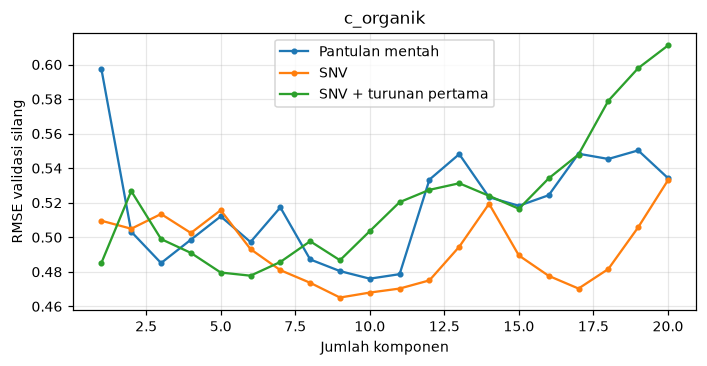

,komponen terbaik,RMSE
Pantulan mentah,10.0,0.476
SNV,9.0,0.465
SNV + turunan pertama,6.0,0.478


In [12]:
SASARAN = 'c_organik'     # ganti dengan 'clay', 'sand', 'ph_h2o', atau 'kpk'
m = data_lab[SASARAN].notna().values
y, pr, Rm = data_lab[SASARAN].values[m], profil[m], R[m]

pisah = GroupShuffleSplit(n_splits=1, test_size=1/3, random_state=7)
i_kal, i_uji = next(pisah.split(Rm, groups=pr))
print('Kalibrasi:', len(i_kal), 'sampel dari', len(set(pr[i_kal])), 'profil')
print('Uji      :', len(i_uji), 'sampel dari', len(set(pr[i_uji])), 'profil')

komp = range(1, 21)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
terbaik = {}
for nama, f in praolah.items():
    B = f(Rm)
    rmse = [ukuran(y[i_kal], cross_val_predict(PLSRegression(k), B[i_kal], y[i_kal], cv=GroupKFold(5), groups=pr[i_kal]))['RMSE'] for k in komp]
    ax.plot(komp, rmse, marker='o', ms=3, label=nama)
    terbaik[nama] = (int(np.argmin(rmse)) + 1, min(rmse))
ax.set(xlabel='Jumlah komponen', ylabel='RMSE validasi silang', title=SASARAN); ax.legend()
plt.tight_layout(); plt.savefig('hasil/pemilihan_komponen.png', dpi=150); plt.show()
pd.DataFrame(terbaik, index=['komponen terbaik', 'RMSE']).T.round(3)

## 9. Model akhir dan penilaian pada profil yang belum pernah dilihat

Setelah satu penilaian, pembagian yang sama diulang 20 kali dengan profil uji yang berbeda. Hasilnya menunjukkan seberapa jauh satu angka dapat bergantung pada profil yang kebetulan terpilih.

Praolah terpilih: SNV | komponen: 9


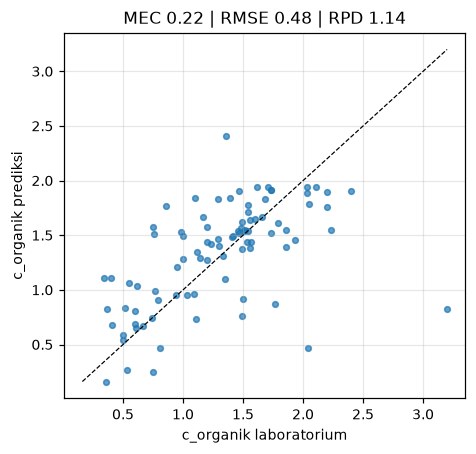

MEC dari 20 pembagian: terendah 0.22, median 0.45, tertinggi 0.60


ME      0.030
RMSE    0.482
MEC     0.223
R2      0.315
RPD     1.141
RPIQ    1.572
dtype: float64

In [13]:
nama_pilih = min(terbaik, key=lambda k: terbaik[k][1])
k_pilih = terbaik[nama_pilih][0]
f = praolah[nama_pilih]
print('Praolah terpilih:', nama_pilih, '| komponen:', k_pilih)

model = PLSRegression(k_pilih).fit(f(Rm)[i_kal], y[i_kal])
p_uji = model.predict(f(Rm)[i_uji]).ravel()
u_uji = ukuran(y[i_uji], p_uji)

fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(y[i_uji], p_uji, s=14, alpha=.7)
b = [min(y[i_uji].min(), p_uji.min()), max(y[i_uji].max(), p_uji.max())]
ax.plot(b, b, 'k--', lw=.8)
ax.set(xlabel=f'{SASARAN} laboratorium', ylabel=f'{SASARAN} prediksi', title=f"MEC {u_uji['MEC']:.2f} | RMSE {u_uji['RMSE']:.2f} | RPD {u_uji['RPD']:.2f}")
plt.tight_layout(); plt.savefig('hasil/prediksi_vs_laboratorium.png', dpi=150); plt.show()

ulang = []
for acak in range(20):
    a, c = next(GroupShuffleSplit(n_splits=1, test_size=1/3, random_state=acak).split(Rm, groups=pr))
    ulang.append(ukuran(y[c], PLSRegression(k_pilih).fit(f(Rm)[a], y[a]).predict(f(Rm)[c]))['MEC'])
print(f'MEC dari 20 pembagian: terendah {min(ulang):.2f}, median {np.median(ulang):.2f}, tertinggi {max(ulang):.2f}')
pd.Series(u_uji).round(3)

## 10. Semua sifat tanah dalam satu tabel

Sifat yang memiliki fitur serapan langsung umumnya lebih mudah dikalibrasi. Hara tersedia, KTK, dan pH tidak memiliki fitur sendiri, sehingga keberhasilannya bergantung pada kovariasi setempat (Modul 7). Tabel berikut memakai validasi silang per profil pada seluruh sampel. Jumlah komponen dipilih hanya dari data latih pada setiap putaran, sehingga angkanya tidak dibuat optimistis oleh pemilihan itu. Agar cepat, spektrum diambil setiap 5 nm.

In [14]:
def cv_bersarang(X, y, gr, kandidat=range(1, 13)):
    p = np.zeros(len(y))
    for latih, uji in GroupKFold(5).split(X, groups=gr):
        nilai = [ukuran(y[latih], cross_val_predict(PLSRegression(k), X[latih], y[latih], cv=GroupKFold(4), groups=gr[latih]))['RMSE'] for k in kandidat]
        k = kandidat[int(np.argmin(nilai))]
        p[uji] = PLSRegression(k).fit(X[latih], y[latih]).predict(X[uji]).ravel()
    return p

A5 = turunan(snv(R))[:, ::5]
ringkas = []
for t in ['c_organik', 'n_total', 'clay', 'silt', 'sand', 'ph_h2o', 'kpk', 'p_tersedia', 'k_tersedia']:
    m = data_lab[t].notna().values
    yt = data_lab[t].values[m]
    ringkas.append({'Sifat': t, 'n': int(m.sum()), 'Rata-rata': yt.mean(), **ukuran(yt, cv_bersarang(A5[m], yt, profil[m]))})
ringkas = pd.DataFrame(ringkas).round(3)
ringkas.to_csv('hasil/metrik_semua_sifat.csv', index=False)
ringkas

,Sifat,n,Rata-rata,ME,RMSE,MEC,R2,RPD,RPIQ
0,c_organik,264,1.333,-0.026,0.497,0.345,0.386,1.238,1.731
1,n_total,265,0.123,0.000,0.031,0.349,0.372,1.242,1.303
2,clay,265,40.476,-0.581,8.609,0.507,0.513,1.428,1.923
3,silt,265,10.258,0.074,4.794,0.162,0.224,1.094,1.293
4,sand,265,49.268,0.654,10.323,0.437,0.446,1.335,1.674
5,ph_h2o,265,5.480,-0.016,0.493,0.248,0.269,1.155,1.804
6,kpk,265,6.612,-0.122,2.593,0.377,0.390,1.269,1.142
7,p_tersedia,265,38.842,0.883,28.365,0.337,0.350,1.230,1.763
8,k_tersedia,265,0.244,0.002,0.153,-0.034,0.045,0.985,1.045


## 11. Memakai model pada spektrum baru

Inilah yang terjadi setelah demonstrasi alat: spektrum baru diberi praolah **yang sama**, lalu dimasukkan ke model. Sembilan sampel yang tidak memiliki hasil laboratorium menjadi contoh yang pas, karena keadaannya sama dengan sampel baru. Nilai prediksinya tidak dapat diperiksa, dan galatnya kira-kira sebesar RMSE pada tabel di atas. Spektrum hasil demonstrasi dapat dimasukkan dengan cara yang sama jika sudah berupa tabel 350–2.500 nm, tetapi hasilnya hanya pendekatan, karena model belajar dari tanah GMP.

In [15]:
model_akhir = PLSRegression(k_pilih).fit(f(Rm), y)
R_baru = tanpa_lab[kolom_spektrum].values[:, pilih]
prediksi_baru = pd.DataFrame({'Sampel': tanpa_lab['sampel'], f'Prediksi {SASARAN}': model_akhir.predict(f(R_baru)).ravel()}).round(2)
prediksi_baru.to_csv('hasil/prediksi_sampel_tanpa_lab.csv', index=False)
prediksi_baru

,Sampel,Prediksi c_organik
0,S47 L5,1.05
1,S73 L1,2.10
2,S73 L2,1.92
3,S73 L3,1.69
4,S73 L4,0.74
5,S45 L1,1.29
6,S45 L2,1.34
7,S45 L3,1.11
8,S45 L4,0.88


## 12. Pengayaan: bagaimana jika hanya punya kanal Sentinel-2?

Spektrum dirata-ratakan ke enam kanal lebar Sentinel-2 dengan pendekatan lebar kanal persegi (bukan fungsi respons sensor yang sebenarnya). Bandingkan kedua sifat: kehilangan informasi akibat kanal lebar tidak sama pada setiap sifat. Data ini tetap merupakan pengukuran dekat di laboratorium, sehingga belum memuat gangguan atmosfer dan penutup lahan yang dihadapi citra satelit.

In [16]:
kanal = {'B02': (458, 523), 'B03': (543, 578), 'B04': (650, 680), 'B08': (785, 900), 'B11': (1565, 1655), 'B12': (2100, 2280)}
S2 = np.column_stack([R[:, (wl >= a) & (wl <= b)].mean(axis=1) for a, b in kanal.values()])
banding = []
for t in ['c_organik', 'clay']:
    m = data_lab[t].notna().values
    yt = data_lab[t].values[m]
    banding.append({'Sifat': t, 'Data': 'Spektrum penuh', **ukuran(yt, cv_bersarang(A5[m], yt, profil[m]))})
    banding.append({'Sifat': t, 'Data': 'Enam kanal gaya Sentinel-2', **ukuran(yt, cv_bersarang(S2[m], yt, profil[m], kandidat=range(1, 7)))})
pd.DataFrame(banding).round(3)

,Sifat,Data,ME,RMSE,MEC,R2,RPD,RPIQ
0,c_organik,Spektrum penuh,-0.026,0.497,0.345,0.386,1.238,1.731
1,c_organik,Enam kanal gaya Sentinel-2,-0.019,0.489,0.367,0.375,1.259,1.760
2,clay,Spektrum penuh,-0.581,8.609,0.507,0.513,1.428,1.923
3,clay,Enam kanal gaya Sentinel-2,-0.086,9.795,0.362,0.363,1.255,1.691
